# DeepLesion Clinical CT Visualization Pipeline

In [1]:
"""
This code is used to connect and mount your Google Drive to your Google Colab
Environment. This file was written in Google a Google Colab Environment.
"""
# import the drive module
from google.colab import drive

# mount your personal google drive filesystem
# at the directory /content/drive to read, write,
# and access files stored in your google drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
'''
Reading in metadata to combine images with bounding box coordinates
'''

import os
import pandas as pd

# Read in csv file with metadata, including bounding box coordinates
google_drive_data_dir = "/content/drive/MyDrive/deep-lesion-data"

# Load Excel metadata
metadata_path = "/content/drive/MyDrive/deep-lesion-data/DL_info.csv"

# Read metadata
df_metadata = pd.read_csv(metadata_path)

# Keep only the columns of interest (File_name, Bounding_boxes, Image_size)
cols_to_keep = ['File_name', 'Bounding_boxes', 'Image_size']
df_metadata = df_metadata[cols_to_keep]

# Create path names to map from the file names in metadata to the image paths we read in from the Google Drive folder
image_paths = {}

for root, _, files in os.walk(google_drive_data_dir):
  for file in files:
    if file.lower().endswith(".png") and not file.startswith("."):
      # Reconstruct path name
      # Get folder name
      folder_name = os.path.basename(root)

      # Get full file name
      full_filename = f"{folder_name}_{file}"

      image_paths[full_filename] = os.path.join(root, file)

print(f"Images found: {len(image_paths)}")

# Add image paths to the relevant rows in df_metadata
df_metadata["Image_path"] = df_metadata["File_name"].map(image_paths)

# Show how many images are matched
print("Matched images:", df_metadata["Image_path"].notna().sum())

display(df_metadata)

Images found: 16419
Matched images: 693


,File_name,Bounding_boxes,Image_size,Image_path
0,000001_01_01_109.png,"226.169, 90.0204, 241.252, 111.977","512, 512",/content/drive/MyDrive/deep-lesion-data/Images...
1,000001_02_01_014.png,"217.396, 284.296, 233.978, 310.294","512, 512",/content/drive/MyDrive/deep-lesion-data/Images...
2,000001_02_01_017.png,"229.412, 258.371, 285.221, 325.763","512, 512",/content/drive/MyDrive/deep-lesion-data/Images...
3,000001_03_01_088.png,"246.735, 128.524, 270.288, 162.618","512, 512",/content/drive/MyDrive/deep-lesion-data/Images...
4,000001_04_01_017.png,"287.217, 206.789, 309.456, 235.585","512, 512",/content/drive/MyDrive/deep-lesion-data/Images...
...,...,...,...,...
32730,004458_01_01_059.png,"376.707, 279.142, 407.198, 315.221","512, 512",NaN
32731,004458_01_01_049.png,"375.941, 291.13, 416.677, 328.028","512, 512",NaN
32732,004458_01_01_047.png,"165.022, 297.592, 209.055, 329.357","512, 512",NaN
32733,004458_01_01_102.png,"215.572, 347.367, 281.457, 373.201","512, 512",NaN


In [128]:
'''
Create a function to extract the lesion based on the bounding box coordinates provided in df_metadata
'''
import numpy as np
from PIL import Image


def get_lesion(image_path, bounding_box, box_adj = 50):
  # Get original pixel values from each image and store as array
  with Image.open(image_path) as img:
    image = np.array(img)

  # Read in coordinates of each corner of bounding box
  x_min, y_min, x_max, y_max = map(
      float, (bounding_box.split(","))
      )

  # Expand bounding box by aditional pixels in every direction
  x_min = int(np.floor(x_min - box_adj))
  y_min = int(np.floor(y_min - box_adj))
  x_max = int(np.ceil(x_max + box_adj))
  y_max = int(np.ceil(y_max + box_adj))

  # Get image dimensions
  height, width = image.shape[:2]

  # Clip coordinates to image boundaries to make sure the box location is valid
  x_min = max(0, x_min)
  y_min = max(0, y_min)
  x_max = min(width, x_max)
  y_max = min(height, y_max)

  # Crop image based on the four coordinates above so we can extract the lesion and some surrounding context
  lesion = image[y_min : y_max, x_min : x_max]

  # Ensure bounding box is valid
  if lesion.size == 0:
    raise ValueError('Invalid or empty lesion bounding box')

  return lesion


In [129]:
'''
Use get_lesion function for images we have in Google Drive to extract lesions and surrounding context
'''

# Subset df_metadata for images which are in Google Drive
df_available = df_metadata[df_metadata['Image_path'].notna()].copy()

# Number lesions within each filename, as there are some images which have more than one
df_available['Lesion_number'] = (
    df_available.groupby("File_name").cumcount() + 1
)

# Create output directory
output_dir = os.path.join(
    google_drive_data_dir,
    "Lesion_Extracts"
)

# Create folder in Google Drive to store extracts
os.makedirs(output_dir, exist_ok = True)

# Create empty lists to append successful and failed lesion crops to for troubleshooting
successful_crop = []
failed_crop = []

# Iterate through rows to extract lesions
for _, row in df_available.iterrows():

  try:

    # Extract lesion
    lesion = get_lesion(row["Image_path"], row["Bounding_boxes"], 50)

    # Create unique filename for lesion
    base_name = os.path.splitext(row["File_name"])[0]

    # Add lesion number to file name
    output_filename = (
        f"{base_name}_lesion{row['Lesion_number']:02d}.png"
    )

    # Create output path
    output_path = os.path.join(output_dir, output_filename)


    # Save image to output path
    Image.fromarray(lesion).save(output_path)

    # Record successful extraction
    successful_crop.append({
        "File_name": row["File_name"],
        "Lesion_number": row["Lesion_number"],
        "Bounding_box": row["Bounding_boxes"],
        "Image_path": row["Image_path"],
        "Crop_path": output_path,
        "Crop_shape": lesion.shape
    })


  except Exception as e:

    # Record failed extraction if failure happens
    failed_crop.append({
        "File_name": row["File_name"],
        "Lesion_number": row["Lesion_number"],
        "Error": str(e)

    })

# Display exraction results
print("Total available lesions: ", len(df_available))
print("Successfully extracted lesions: ", len(successful_crop))
print("Failed lesion extractions: ", len(failed_crop))

print("\n For reference, lesion crops saved to: ", output_dir)


Total available lesions:  693
Successfully extracted lesions:  693
Failed lesion extractions:  0

 For reference, lesion crops saved to:  /content/drive/MyDrive/deep-lesion-data/Lesion_Extracts


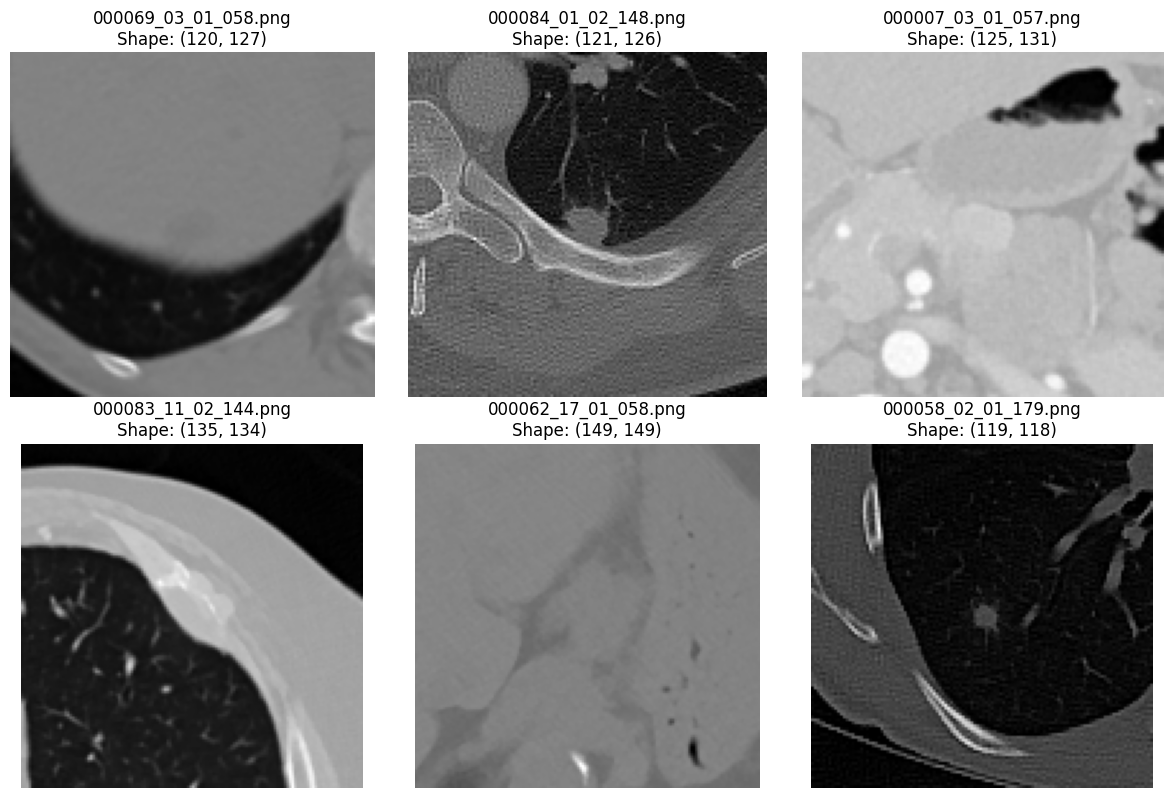

In [130]:
'''
Visualize sample of cropped lesions to test
'''

import matplotlib.pyplot as plt
import random

# Select random successful crops
samples = random.sample(successful_crop, 6)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, sample in zip(axes.flat, samples):
    image = np.array(Image.open(sample["Crop_path"]))

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"{sample['File_name']}\n"
        f"Shape: {image.shape[:2]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

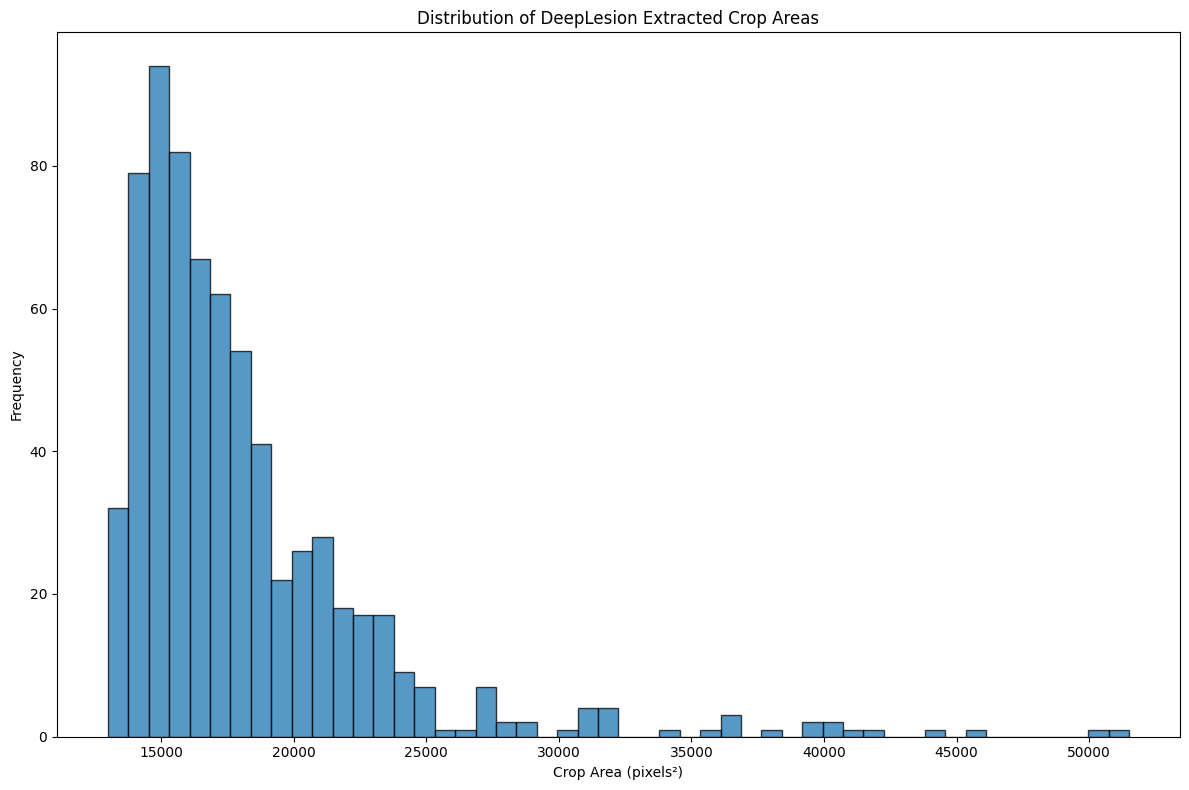

In [131]:
import matplotlib.pyplot as plt

# Extract crop dimensions
heights = [crop["Crop_shape"][0] for crop in successful_crop]
widths = [crop["Crop_shape"][1] for crop in successful_crop]

# Calculate areas
areas = [h * w for h, w in zip(heights, widths)]


# Create and format histogram
plt.figure(figsize=(12, 8))

plt.hist(areas, bins=50, edgecolor="black", alpha=0.75)

plt.xlabel("Crop Area (pixels²)")
plt.ylabel("Frequency")
plt.title("Distribution of DeepLesion Extracted Crop Areas")

plt.tight_layout()
plt.show()

In [158]:
'''
Now, we will extract one non-lesion sample from each original image

Note that we will have fewer of these because some images have multiple lesions and because we want to ensure we have sufficient non-blank space
We also have selection criteria outlined in the code to ensure we don't include more than a threshold proportion of blank space or the lesion
'''

def get_context(
    image_path,
    bounding_boxes,
    box_adj = 50,
    intensity_threshold = 50,
    min_tissue_fraction = 0.95,
    min_size = 100,
    max_size = 125,
    max_attempts = 5000
):

  # Load original image
  with Image.open(image_path) as img:
    image = np.array(img)

  height, width = image.shape[:2]

  # Convert image to grayscale for tissue detection (tissue is bright, blank space is dark)
  if image.ndim == 3:
    grayscale = np.mean(image, axis = 2)
  else:
    grayscale = image

  # Use mask to only keep crops with specified fraction of pixels above threshold value (to classify as tissue and not blank space)
  tissue_mask = grayscale > intensity_threshold

  # Store bounding boxes which we will exclude from candidates
  exclusion_boxes = []

  for bounding_box in bounding_boxes:
    x_min, y_min, x_max, y_max = map(
            float, bounding_box.split(",")
        )

    # Expand bounding box by additional pixels
    x_min = int(np.floor(x_min - box_adj))
    y_min = int(np.floor(y_min - box_adj))
    x_max = int(np.ceil(x_max + box_adj))
    y_max = int(np.ceil(y_max + box_adj))

    # Clip coordinates to image boundaries
    x_min = max(0, x_min)
    y_min = max(0, y_min)
    x_max = min(width, x_max)
    y_max = min(height, y_max)

    exclusion_boxes.append(
        (x_min, y_min, x_max, y_max)
    )

  # Randomly search for a valid candidate
  for _ in range(max_attempts):

    # Choose crop dimensions within predefined boundaries
    crop_height = np.random.randint(
        min_size, min(max_size, height) + 1
    )

    crop_width = np.random.randint(
        min_size, min(max_size, width) + 1
    )

    # Restrict candidate selection to the central image region
    min_x = int(width * 0.25)
    max_x = int(width * 0.75) - crop_width

    min_y = int(height * 0.25)
    max_y = int(height * 0.75) - crop_height

    # Ensure crop fits within the selection region
    if max_x < min_x or max_y < min_y:
      continue

    # Randomly select crop coordinates
    x_min = np.random.randint(min_x, max_x + 1)
    y_min = np.random.randint(min_y, max_y + 1)

    # Calculate bottom-right coordinates of candidate crop
    x_max = x_min + crop_width
    y_max = y_min + crop_height

    # Check if crop passes through bounded box we need to exclude
    # Evaluates horizontal and vertical directions
    # If all four conditions are true, the rectangles overlap
    # If any condition is false, the rectangles do not overlap
    overlaps_lesion = any(
          x_min < bx_max and x_max > bx_min
          and y_min < by_max and y_max > by_min
          for bx_min, by_min, bx_max, by_max in exclusion_boxes
      )

    if overlaps_lesion:
      continue

    # Now test tissue presence via brightness
    candidate_mask = tissue_mask[y_min : y_max, x_min : x_max]

    # Calculate proportion of image considered tissue based on average brightness
    tissue_fraction = np.mean(candidate_mask)

    # If too much background (too much blank space), reject
    if tissue_fraction < min_tissue_fraction:
      continue

    # Otherwise, extract valid crop
    context = image[y_min : y_max, x_min : x_max]

    return context, (x_min, y_min, x_max, y_max), tissue_fraction

  # If cannot find crop for the image after maximum attempts, raise error
  raise ValueError(
      "Could not find valid context crop for this image after maximum attempts."
  )

In [159]:
'''
Now, we will extract the context crops for the whole dataset

'''

# Group metadata by original image
# This helps because some images have multiple lesions and therefore multiple rows in metadata
image_groups = df_available.groupby("File_name")

# Create output directory
context_output_dir = os.path.join(
    google_drive_data_dir,
    "Context_Extracts"
)

# Set up directory in Drive
os.makedirs(context_output_dir, exist_ok=True)

# Create empty lists for successful and failed extractions
successful_context = []
failed_context = []


# Set random seed for reproducibility
np.random.seed(54)

# Iterate through unique original images
for file_name, group in image_groups:

    try:

        # Get image path
        image_path = group.iloc[0]["Image_path"]

        # Get all lesion bounding boxes associated with image
        bounding_boxes = group["Bounding_boxes"].tolist()

        # Extract negative tissue crop
        context, context_box, tissue_fraction = get_context(
            image_path=image_path,
            bounding_boxes=bounding_boxes,
            box_adj=50,
            intensity_threshold=10,
            min_tissue_fraction=0.50,
            min_size=150,
            max_size=350,
            max_attempts=5000
        )

       # Create unique filename
        base_name = os.path.splitext(file_name)[0]
        output_filename = f"{base_name}_context.png"

        # Create output path
        output_path = os.path.join(
            context_output_dir,
            output_filename
        )

        # Save negative crop
        Image.fromarray(context).save(output_path)

        # Record successful extraction
        successful_context.append({
            "File_name": file_name,
            "Context_box": context_box,
            "Image_path": image_path,
            "Context_path": output_path,
            "Context_shape": context.shape,
            "Tissue_fraction": tissue_fraction
        })

    except Exception as e:

        # Record failed extraction
        failed_context.append({
            "File_name": file_name,
            "Error": str(e)
        })


# Display extraction results
print("Total original images:", len(image_groups))
print("Successfully extracted:", len(successful_context))
print("Failed extractions:", len(failed_context))
print("Context crops saved to:", context_output_dir)



Total original images: 678
Successfully extracted: 222
Failed extractions: 456
Context crops saved to: /content/drive/MyDrive/deep-lesion-data/Context_Extracts


In [160]:
'''
Create a function we can use to plot the lesion extraction and context extraction on top of each image for visual inspection
'''

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def plot_extractions(file_name, df_available, successful_context,
                     successful_crop, box_adj = 50):

  # Get metadata for the original image
    group = df_available[
        df_available["File_name"] == file_name
    ]

    # Get original image path
    image_path = group.iloc[0]["Image_path"]

    # Load original image
    with Image.open(image_path) as img:
        image = np.array(img)

    height, width = image.shape[:2]

    # Create figure
    fig, ax = plt.subplots(figsize=(10, 10))

    ax.imshow(image, cmap="gray")

    # Plot all lesion crops in green
    for _, row in group.iterrows():

        # Read original lesion bounding box
        x_min, y_min, x_max, y_max = map(
            float, row["Bounding_boxes"].split(",")
        )

        # Expand bounding box by 50 pixels to match what we extracted
        x_min = max(0, int(np.floor(x_min - box_adj)))
        y_min = max(0, int(np.floor(y_min - box_adj)))
        x_max = min(width, int(np.ceil(x_max + box_adj)))
        y_max = min(height, int(np.ceil(y_max + box_adj)))

        # Draw green rectangle
        rect = Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            linewidth=2,
            edgecolor="green",
            facecolor="none"
        )

        ax.add_patch(rect)

    # Find context crop for this image
    context_record = next(
        (
            crop for crop in successful_context
            if crop["File_name"] == file_name
        ),
        None
    )

    # Plot negative crop in red
    if context_record is not None:

        x_min, y_min, x_max, y_max = context_record["Context_box"]

        rect = Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

    # Format plot
    ax.set_title(f"Lesion and Non-Lesion Extraction: {file_name}")
    ax.axis("off")

    # Add legend
    legend_elements = [
        Rectangle(
            (0, 0), 1, 1,
            edgecolor="green",
            facecolor="none",
            linewidth=2,
            label="Lesion crop"
        ),
        Rectangle(
            (0, 0), 1, 1,
            edgecolor="red",
            facecolor="none",
            linewidth=2,
            label="Non-lesion crop"
        )
    ]

    ax.legend(handles=legend_elements, loc="upper right")

    plt.tight_layout()
    plt.show()


In [161]:
# Find images with successful context extractions
context_files = {
    record["File_name"] for record in successful_context
}

# Find images with successful lesion extractions
lesion_files = {
    record["File_name"] for record in successful_crop
}

# Find images with both
common_files = list(context_files.intersection(lesion_files))

print("Images with both extractions:", len(common_files))

Images with both extractions: 222


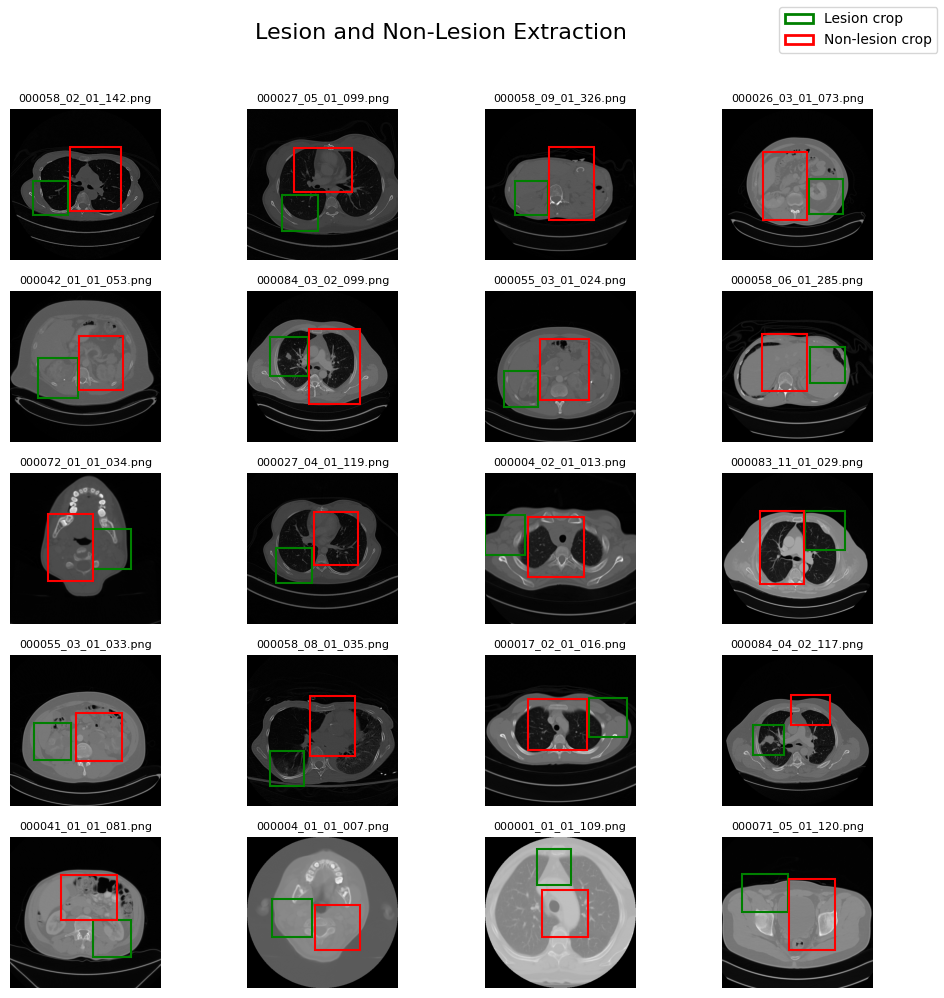

In [162]:
random_files = random.sample(
    common_files,
    min(20, len(common_files))
)

fig, axes = plt.subplots(5, 4, figsize=(10, 10))

for ax, file_name in zip(axes.flatten(), random_files):

    # Get metadata
    group = df_available[
        df_available["File_name"] == file_name
    ]

    image_path = group.iloc[0]["Image_path"]

    # Load original image
    with Image.open(image_path) as img:
        image = np.array(img)

    height, width = image.shape[:2]

    ax.imshow(image, cmap="gray")

    # Plot lesion crops in green
    for _, row in group.iterrows():

        x_min, y_min, x_max, y_max = map(
            float, row["Bounding_boxes"].split(",")
        )

        x_min = max(0, int(np.floor(x_min - 50)))
        y_min = max(0, int(np.floor(y_min - 50)))
        x_max = min(width, int(np.ceil(x_max + 50)))
        y_max = min(height, int(np.ceil(y_max + 50)))

        ax.add_patch(Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            linewidth=1.5,
            edgecolor="green",
            facecolor="none"
        ))

    # Plot negative crop in red
    context_record = next(
        r for r in successful_context
        if r["File_name"] == file_name
    )

    x_min, y_min, x_max, y_max = context_record["Context_box"]

    ax.add_patch(Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        linewidth=1.5,
        edgecolor="red",
        facecolor="none"
    ))

    ax.set_title(file_name, fontsize=8)
    ax.axis("off")

# Hide unused subplot axes
for ax in axes.flatten()[len(random_files):]:
    ax.axis("off")

# Add legend
legend_elements = [
    Rectangle((0, 0), 1, 1, edgecolor="green",
              facecolor="none", linewidth=2, label="Lesion crop"),
    Rectangle((0, 0), 1, 1, edgecolor="red",
              facecolor="none", linewidth=2, label="Non-lesion crop")
]

fig.legend(handles=legend_elements, loc="upper right")

fig.suptitle("Lesion and Non-Lesion Extraction", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()